uma alternativa de puxar dados é:


```python
from ucimlrepo import fetch_ucirepo # dados com o pacote ucimlrepo mas talvez precise pip install ucimlrepo
wine = fetch_ucirepo(id=109) #109 é o de wine mesmo, tem um de wine quality (id 196) mas é outro
X = wine.data.features
y = wine.data.targets
```


In [10]:
from sklearn.datasets import load_wine #o banco de dados do vinho já tem no sklearn.datasets

wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Z = (X - X.mean()) / X.std() #padronização de X

In [3]:
S = Z.cov()#matriz de covariância
R = Z.corr()#matriz de correlação

#como já padronizei os dados S = R, então posso usar qualquer uma das duas para fazer a ACP.


In [4]:
R

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
alcohol,1.000000,0.094397,0.211545,-0.310235,0.270798,0.289101,0.236815,-0.155929,0.136698,0.546364,-0.071747,0.072343,0.643720
malic_acid,0.094397,1.000000,0.164045,0.288500,-0.054575,-0.335167,-0.411007,0.292977,-0.220746,0.248985,-0.561296,-0.368710,-0.192011
ash,0.211545,0.164045,1.000000,0.443367,0.286587,0.128980,0.115077,0.186230,0.009652,0.258887,-0.074667,0.003911,0.223626
alcalinity_of_ash,-0.310235,0.288500,0.443367,1.000000,-0.083333,-0.321113,-0.351370,0.361922,-0.197327,0.018732,-0.273955,-0.276769,-0.440597
magnesium,0.270798,-0.054575,0.286587,-0.083333,1.000000,0.214401,0.195784,-0.256294,0.236441,0.199950,0.055398,0.066004,0.393351
total_phenols,0.289101,-0.335167,0.128980,-0.321113,0.214401,1.000000,0.864564,-0.449935,0.612413,-0.055136,0.433681,0.699949,0.498115
flavanoids,0.236815,-0.411007,0.115077,-0.351370,0.195784,0.864564,1.000000,-0.537900,0.652692,-0.172379,0.543479,0.787194,0.494193
nonflavanoid_phenols,-0.155929,0.292977,0.186230,0.361922,-0.256294,-0.449935,-0.537900,1.000000,-0.365845,0.139057,-0.262640,-0.503270,-0.311385
proanthocyanins,0.136698,-0.220746,0.009652,-0.197327,0.236441,0.612413,0.652692,-0.365845,1.000000,-0.025250,0.295544,0.519067,0.330417
color_intensity,0.546364,0.248985,0.258887,0.018732,0.199950,-0.055136,-0.172379,0.139057,-0.025250,1.000000,-0.521813,-0.428815,0.316100


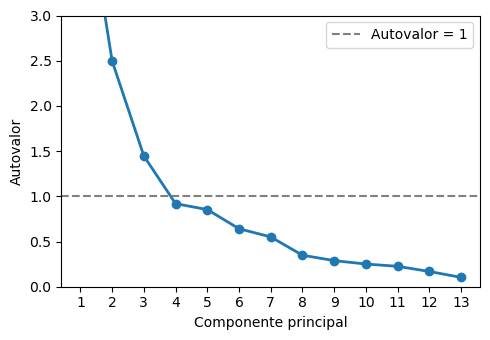

In [5]:
autovalores, E = np.linalg.eigh(R)
# A função eigh() devolve os autovalores em ordem crescente, então precisamos inverter a ordem
ordem = autovalores.argsort()[::-1]
autovalores = autovalores[ordem]
E = E[:, ordem]

# O sinal de um autovetor é arbitrário. Escolhemos a orientação dos dois primeiros para facilitar a interpretação.
if E[2, 0] < 0:
    E[:, 0] *= -1
if E[1, 1] < 0:
    E[:, 1] *= -1

# Os escores T são
T = Z.to_numpy() @ E

# Variância explicada pelos componentes principais
proporcoes = autovalores / autovalores.sum()
acumuladas = np.cumsum(proporcoes)

tabela_CPs = pd.DataFrame({
    "Componente": [f"CP{i+1}" for i in range(len(autovalores))],
    "Autovalor": autovalores,
    "Proporção (%)": 100 * proporcoes,
    "Acumulada (%)": 100 * acumuladas,
}).round(2).set_index("Componente").rename_axis(None)
# Gráfico do cotovelo
componentes = np.arange(1, len(autovalores) + 1)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(componentes, autovalores, "o-", linewidth=2)
ax.axhline(1, color="gray", linestyle="--", label="Autovalor = 1")
ax.set(
    xlabel="Componente principal",
    ylabel="Autovalor",
    xticks=componentes,
    ylim=(0, 3),
)
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
tabela_CPs

,Autovalor,Proporção (%),Acumulada (%)
CP1,4.71,36.20,36.20
CP2,2.50,19.21,55.41
CP3,1.45,11.12,66.53
CP4,0.92,7.07,73.60
CP5,0.85,6.56,80.16
CP6,0.64,4.94,85.10
CP7,0.55,4.24,89.34
CP8,0.35,2.68,92.02
CP9,0.29,2.22,94.24
CP10,0.25,1.93,96.17


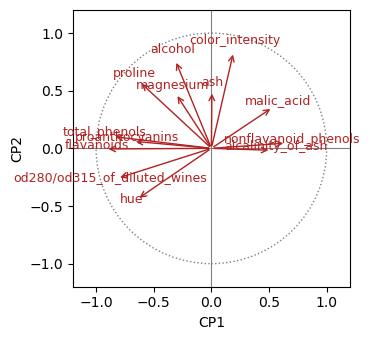

In [7]:
correlacoes = E[:, :2] * np.sqrt(autovalores[:2])

pd.DataFrame({
    "Variável": Z.columns,
    "CP1": correlacoes[:, 0],
    "CP2": correlacoes[:, 1],
}).round(3).set_index("Variável").rename_axis(None)
fig, ax = plt.subplots(figsize=(5, 3.5))

ajuste_vertical = {
    "Comp. da nadadeira": -0.10,
    "Massa corporal": 0.10,
}

for nome, (x, y) in zip(Z.columns, correlacoes):
    ax.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "firebrick"},
    )
    ax.text(
        1.08 * x,
        1.08 * y + ajuste_vertical.get(nome, 0),
        nome,
        color="firebrick",
        fontsize=9,
        ha="center",
    )

ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="gray", linestyle=":"))
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(
    xlabel="CP1",
    ylabel="CP2",
    xlim=(-1.2, 1.2),
    ylim=(-1.2, 1.2),
)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()